# 01 · Exploración del dataset PKLot

**TP Visión por Computadora 2 — CEIA — Grupo 8**

**Objetivo del proyecto:** detectar espacios de estacionamiento **libres** y **ocupados** sobre la imagen completa
de un estacionamiento usando un modelo de detección de objetos, comparar al menos dos arquitecturas
(precision, recall, F1, mAP, tiempo de inferencia), calcular el **porcentaje de ocupación** y hacer una demo sobre video.

**Objetivo de este notebook:** entender el dataset antes de modelar:

1. Estructura y formato de las anotaciones (COCO).
2. Tamaño de los splits y balance de clases.
3. Cámaras / estacionamientos presentes y su distribución.
4. Distribución temporal (fecha y hora de captura).
5. Geometría de las bounding boxes (tamaño, forma, posición, solapamiento).
6. Ocupación por imagen.
7. Visualización de ejemplos y casos raros (imágenes sin anotar).
8. Riesgos de *data leakage* entre splits.
9. Conclusiones y decisiones para la etapa de modelado.

**Fuente:** [PKLot en Kaggle](https://www.kaggle.com/datasets/ammarnassanalhajali/pklot-dataset) (export de Roboflow, *PKLot v2 640*).
Almeida, P., Oliveira, L. S., Silva Jr, E., Britto Jr, A., Koerich, A., *PKLot – A robust dataset for parking lot classification*,
Expert Systems with Applications, 42(11):4937-4949, 2015.

## 0. Setup

In [1]:
import json
import re
from collections import Counter
from pathlib import Path

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image

%config InlineBackend.figure_format = "jpeg"  # mantiene liviano el .ipynb versionado
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
RNG = np.random.default_rng(42)

# El notebook vive en notebooks/, el dataset en <repo>/archive (no versionado)
REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = REPO_ROOT / "archive"
SPLITS = ["train", "valid", "test"]

assert DATA_DIR.exists(), f"No se encontró el dataset en {DATA_DIR}. Ver README para descargarlo."
print("Dataset en:", DATA_DIR)
for s in SPLITS:
    n = sum(1 for _ in (DATA_DIR / s).glob("*.jpg"))
    print(f"  {s:5s}: {n:5d} imágenes")

Dataset en: E:\UBA\5B2026\VpC2\VpC2-Grupo8\archive
  train:  8691 imágenes
  valid:  2483 imágenes
  test :  1242 imágenes


## 1. Formato de las anotaciones

Cada split trae un `_annotations.coco.json` en formato **COCO**. Las bounding boxes están en `[x, y, w, h]`
(esquina superior izquierda + ancho/alto, en píxeles de la imagen ya redimensionada a 640×640).

In [2]:
with open(DATA_DIR / "test" / "_annotations.coco.json") as f:
    sample = json.load(f)

print("Claves:", list(sample.keys()))
print("\ninfo:", sample["info"])
print("\ncategories:")
for c in sample["categories"]:
    print("  ", c)
print("\nEjemplo de image:", sample["images"][0])
print("Ejemplo de annotation:", sample["annotations"][0])
del sample

Claves: ['info', 'licenses', 'categories', 'images', 'annotations']

info: {'year': '2021', 'version': '2', 'description': 'Exported from roboflow.ai', 'contributor': 'Universidade Federal do Parana', 'url': 'https://public.roboflow.ai/object-detection/pklot', 'date_created': '2021-01-05T21:55:12+00:00'}

categories:
   {'id': 0, 'name': 'spaces', 'supercategory': 'none'}
   {'id': 1, 'name': 'space-empty', 'supercategory': 'spaces'}
   {'id': 2, 'name': 'space-occupied', 'supercategory': 'spaces'}

Ejemplo de image: {'id': 0, 'license': 1, 'file_name': '2012-11-06_13_43_31_jpg.rf.00207754dbce0d625d24ca31898fcfd7.jpg', 'height': 640, 'width': 640, 'date_captured': '2021-01-05T21:55:12+00:00'}
Ejemplo de annotation: {'id': 0, 'image_id': 0, 'category_id': 1, 'bbox': [139, 165, 23, 40], 'area': 920, 'segmentation': [], 'iscrowd': 0}


Hay 3 categorías declaradas, pero `spaces` (id 0) es sólo la *supercategoría* que genera Roboflow:
las anotaciones usan únicamente **`space-empty` (1)** y **`space-occupied` (2)**. Lo verificamos abajo.

Cargamos todo en dos DataFrames: uno de imágenes y otro de anotaciones (una fila por box).

In [3]:
FNAME_RE = re.compile(r"^(\d{4}-\d{2}-\d{2})_(\d{2})_(\d{2})_(\d{2})")


def load_split(split: str) -> tuple[pd.DataFrame, pd.DataFrame, dict]:
    with open(DATA_DIR / split / "_annotations.coco.json") as f:
        coco = json.load(f)
    cats = {c["id"]: c["name"] for c in coco["categories"]}

    imgs = pd.DataFrame(coco["images"])[["id", "file_name", "width", "height"]]
    imgs = imgs.rename(columns={"id": "image_id"})
    imgs["split"] = split

    anns = pd.DataFrame(coco["annotations"])[["id", "image_id", "category_id", "bbox", "area"]]
    anns[["x", "y", "w", "h"]] = pd.DataFrame(anns["bbox"].tolist(), index=anns.index)
    anns = anns.drop(columns="bbox")
    anns["category"] = anns["category_id"].map(cats)
    anns["split"] = split
    return imgs, anns, cats


parts = [load_split(s) for s in SPLITS]
images = pd.concat([p[0] for p in parts], ignore_index=True)
annots = pd.concat([p[1] for p in parts], ignore_index=True)
CATS = parts[0][2]
del parts

# Fecha y hora de captura, codificadas en el nombre original del archivo
dt = images["file_name"].str.extract(FNAME_RE)
images["datetime"] = pd.to_datetime(dt[0] + " " + dt[1] + ":" + dt[2] + ":" + dt[3])
images["date"] = images["datetime"].dt.date
images["hour"] = images["datetime"].dt.hour

print(f"{len(images):,} imágenes | {len(annots):,} anotaciones")
print("Categorías usadas:", annots["category"].value_counts().to_dict())
print("Tamaños de imagen:", images.groupby(["width", "height"]).size().to_dict())
images.head()

12,416 imágenes | 711,856 anotaciones
Categorías usadas: {'space-empty': 376121, 'space-occupied': 335735}
Tamaños de imagen: {(640, 640): 12416}


,image_id,file_name,width,height,split,datetime,date,hour
0,0,2013-04-10_12_00_06_jpg.rf.bef78f7879666a6d899...,640,640,train,2013-04-10 12:00:06,2013-04-10,12
1,1,2012-10-28_15_07_11_jpg.rf.bf0215bf1be731828c9...,640,640,train,2012-10-28 15:07:11,2012-10-28,15
2,2,2012-10-15_15_16_04_jpg.rf.bf069ee1dcc96c9e5c2...,640,640,train,2012-10-15 15:16:04,2012-10-15,15
3,3,2013-03-20_11_50_06_jpg.rf.bf0daeaae52ff23b8cc...,640,640,train,2013-03-20 11:50:06,2013-03-20,11
4,4,2012-12-24_09_50_05_jpg.rf.bf1406d0cd01a8d266d...,640,640,train,2012-12-24 09:50:05,2012-12-24,9


## 2. Tamaño de los splits y balance de clases

In [4]:
n_ann = annots.groupby(["split", "image_id"]).size().rename("n_annots")
images = images.merge(n_ann, left_on=["split", "image_id"], right_index=True, how="left")
images["n_annots"] = images["n_annots"].fillna(0).astype(int)

summary = pd.DataFrame({
    "imagenes": images.groupby("split").size(),
    "imgs_sin_anotar": images[images["n_annots"] == 0].groupby("split").size(),
    "anotaciones": annots.groupby("split").size(),
    "empty": annots[annots["category"] == "space-empty"].groupby("split").size(),
    "occupied": annots[annots["category"] == "space-occupied"].groupby("split").size(),
}).loc[SPLITS]
summary["% imgs"] = (100 * summary["imagenes"] / summary["imagenes"].sum()).round(1)
summary["% empty"] = (100 * summary["empty"] / summary["anotaciones"]).round(1)
summary

,imagenes,imgs_sin_anotar,anotaciones,empty,occupied,% imgs,% empty
split,,,,,,,
train,8691,189,497856,265908,231948,70.0,53.4
valid,2483,59,143316,73629,69687,20.0,51.4
test,1242,26,70684,36584,34100,10.0,51.8


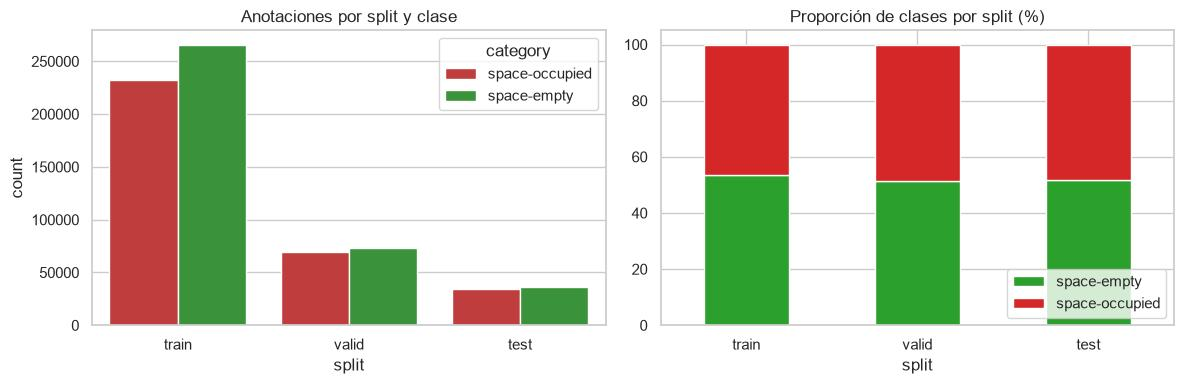

In [5]:
PALETTE = {"space-empty": "#2ca02c", "space-occupied": "#d62728"}

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=annots, x="split", hue="category", order=SPLITS, palette=PALETTE, ax=ax[0])
ax[0].set_title("Anotaciones por split y clase")
(annots.groupby("split")["category"].value_counts(normalize=True).unstack().loc[SPLITS] * 100).plot(
    kind="bar", stacked=True, color=PALETTE, ax=ax[1], rot=0)
ax[1].set_title("Proporción de clases por split (%)")
ax[1].legend(loc="lower right")
plt.tight_layout()

## 3. Cámaras / estacionamientos

El PKLot original tiene 3 escenas: **PUCPR** (10º piso, ~100 plazas), **UFPR04** (4º piso, 28 plazas)
y **UFPR05** (5º piso, ~40 plazas). La versión de Roboflow **perdió la carpeta de origen** (y también la
etiqueta de clima: *sunny / cloudy / rainy*), pero como cada cámara tiene un número fijo de plazas anotadas,
podemos **recuperar la cámara a partir de la cantidad de anotaciones por imagen**.

In [6]:
print("Cantidad de anotaciones por imagen (valores distintos):")
print(images["n_annots"].value_counts().sort_index())

CAMERA_BY_N = {100: "PUCPR", 40: "UFPR05", 28: "UFPR04", 0: "sin_anotar"}
images["camera"] = images["n_annots"].map(CAMERA_BY_N).fillna("otra")
annots = annots.merge(images[["split", "image_id", "camera", "hour", "date"]], on=["split", "image_id"], how="left")

pd.crosstab(images["camera"], images["split"], margins=True)[SPLITS + ["All"]]

Cantidad de anotaciones por imagen (valores distintos):
n_annots
0       274
28     3517
40     4152
100    4473
Name: count, dtype: int64


split,train,valid,test,All
camera,,,,
PUCPR,3128,907,438,4473
UFPR04,2492,672,353,3517
UFPR05,2882,845,425,4152
sin_anotar,189,59,26,274
All,8691,2483,1242,12416


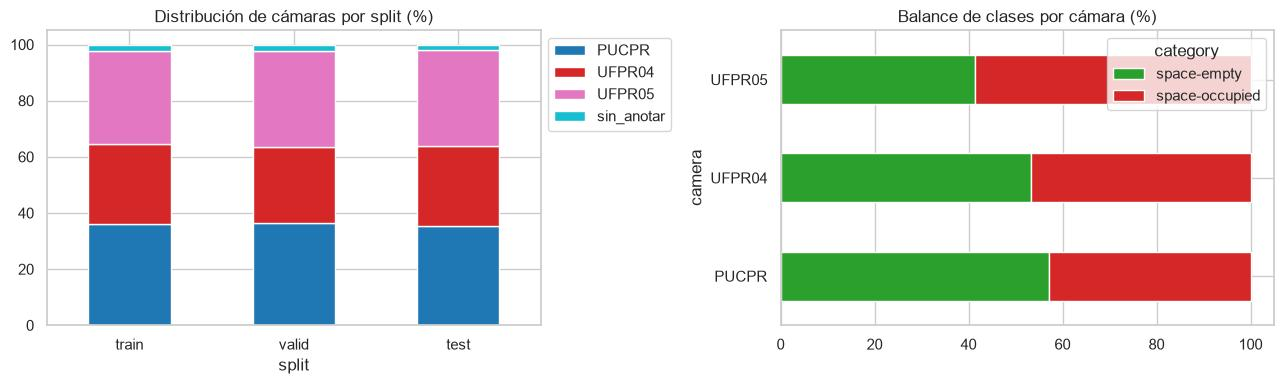

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
pd.crosstab(images["split"], images["camera"], normalize="index").loc[SPLITS].mul(100).plot(
    kind="bar", stacked=True, rot=0, ax=ax[0], colormap="tab10")
ax[0].set_title("Distribución de cámaras por split (%)")
ax[0].legend(bbox_to_anchor=(1, 1))

occ_cam = annots.groupby("camera")["category"].value_counts(normalize=True).unstack().mul(100)
occ_cam.plot(kind="barh", stacked=True, color=PALETTE, ax=ax[1])
ax[1].set_title("Balance de clases por cámara (%)")
plt.tight_layout()

## 4. Distribución temporal

Fecha y hora vienen en el nombre de archivo (`YYYY-MM-DD_HH_MM_SS_jpg.rf.<hash>.jpg`).
Las capturas originales se tomaron cada ~5 minutos durante el día.

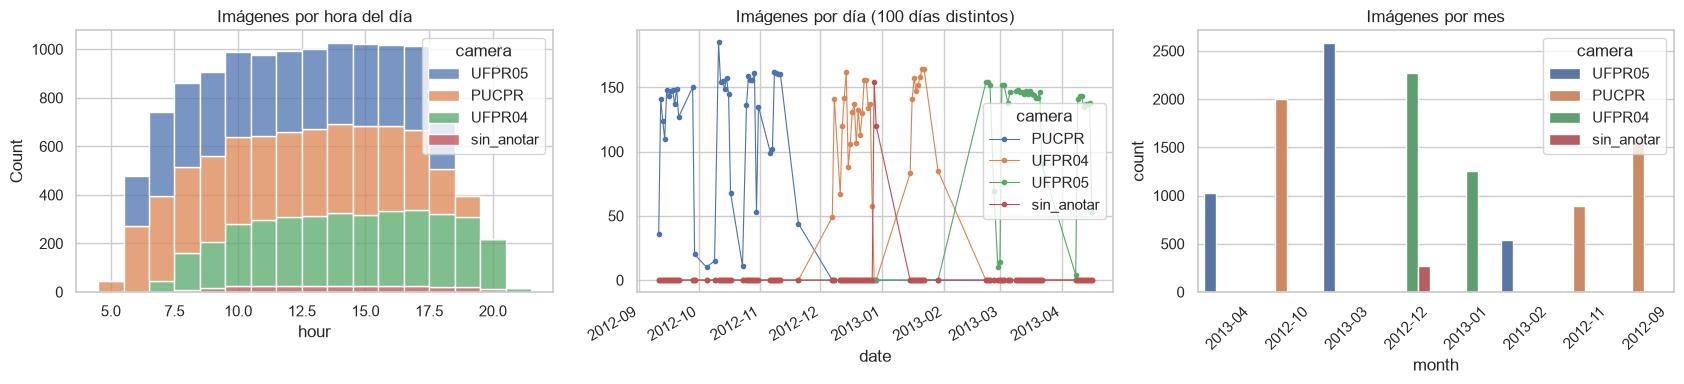

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(data=images, x="hour", hue="camera", multiple="stack", discrete=True, ax=ax[0])
ax[0].set_title("Imágenes por hora del día")

per_day = images.groupby(["date", "camera"]).size().unstack(fill_value=0)
per_day.index = pd.to_datetime(per_day.index)
per_day.plot(ax=ax[1], marker=".", lw=0.8)
ax[1].set_title(f"Imágenes por día ({images['date'].nunique()} días distintos)")

images["month"] = images["datetime"].dt.to_period("M").astype(str)
sns.countplot(data=images, x="month", hue="camera", ax=ax[2])
ax[2].tick_params(axis="x", rotation=45)
ax[2].set_title("Imágenes por mes")
plt.tight_layout()

## 5. Ocupación por imagen

Esta es la métrica de negocio que vamos a reportar en la demo: `% ocupación = ocupados / (ocupados + libres)`.

,count,mean,std,min,25%,50%,75%,max
camera,,,,,,,,
PUCPR,4473.0,0.430,0.368,0.0,0.02,0.470,0.770,1.0
UFPR04,3517.0,0.468,0.435,0.0,0.00,0.357,0.964,1.0
UFPR05,4152.0,0.587,0.421,0.0,0.10,0.800,0.975,1.0


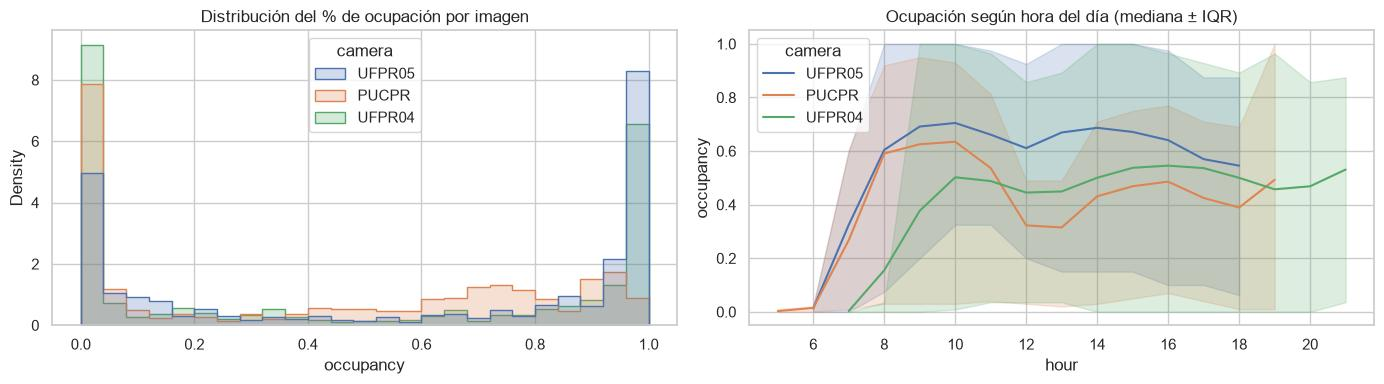

In [9]:
occ = (annots.assign(occupied=annots["category"] == "space-occupied")
       .groupby(["split", "image_id"])
       .agg(occupied=("occupied", "sum"), total=("occupied", "size")))
occ["occupancy"] = occ["occupied"] / occ["total"]
images = images.merge(occ[["occupancy"]], left_on=["split", "image_id"], right_index=True, how="left")

cams = ["PUCPR", "UFPR04", "UFPR05"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=images[images["camera"].isin(cams)], x="occupancy", hue="camera",
             bins=25, element="step", stat="density", common_norm=False, ax=ax[0])
ax[0].set_title("Distribución del % de ocupación por imagen")
sns.lineplot(data=images[images["camera"].isin(cams)], x="hour", y="occupancy", hue="camera",
             errorbar=("pi", 50), ax=ax[1])
ax[1].set_title("Ocupación según hora del día (mediana ± IQR)")
plt.tight_layout()

images[images["camera"].isin(cams)].groupby("camera")["occupancy"].describe().round(3)

## 6. Geometría de las bounding boxes

Las imágenes originales (1280×720) fueron **estiradas a 640×640** por Roboflow, y las plazas originalmente
se anotaron como **rectángulos rotados** que Roboflow convirtió a cajas alineadas a los ejes (*axis-aligned*).
Ambas cosas afectan la forma y el solapamiento de las cajas.

              w         h    aspect   area_px      side
count  711856.0  711856.0  711856.0  711856.0  711856.0
mean       33.7      51.5       0.6    1901.8      41.1
std        15.7      14.8       0.2    1591.7      14.5
min        16.0      33.0       0.4     544.0      23.3
25%        22.5      41.0       0.5     940.0      30.7
50%        27.0      50.0       0.6    1439.2      37.9
75%        41.5      55.0       0.7    2160.0      46.5
max        93.0     132.5       1.4   10666.2     103.3


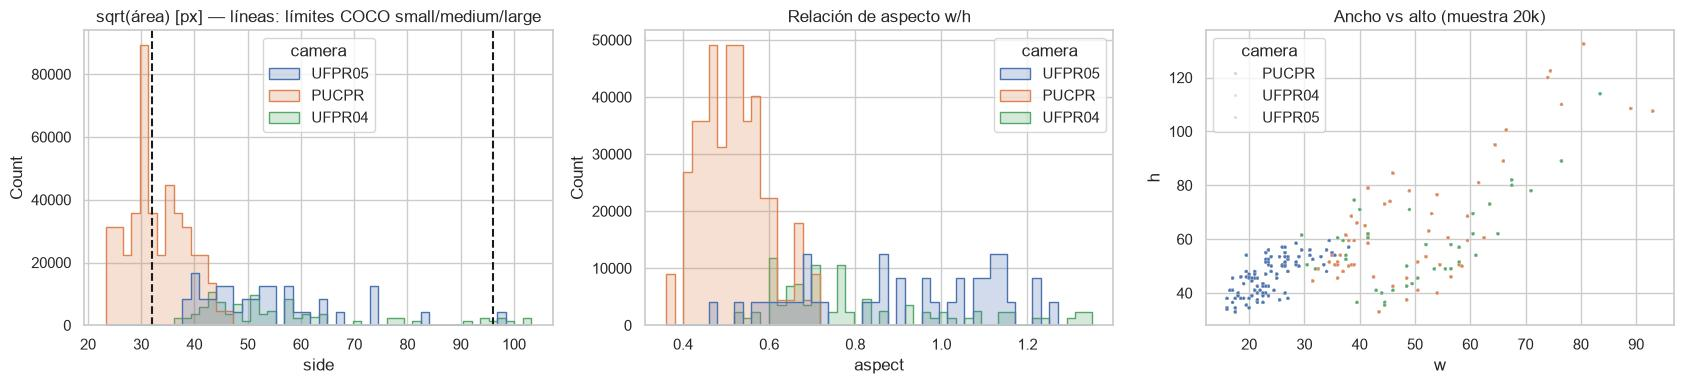

In [10]:
annots["aspect"] = annots["w"] / annots["h"]
annots["area_px"] = annots["w"] * annots["h"]
annots["side"] = np.sqrt(annots["area_px"])

print(annots[["w", "h", "aspect", "area_px", "side"]].describe().round(1))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(data=annots, x="side", hue="camera", bins=50, element="step", ax=ax[0])
ax[0].axvline(32, ls="--", c="k"); ax[0].axvline(96, ls="--", c="k")
ax[0].set_title("sqrt(área) [px] — líneas: límites COCO small/medium/large")
sns.histplot(data=annots, x="aspect", hue="camera", bins=50, element="step", ax=ax[1])
ax[1].set_title("Relación de aspecto w/h")
sample_b = annots.sample(20_000, random_state=0)
sns.scatterplot(data=sample_b, x="w", y="h", hue="camera", s=5, alpha=0.3, ax=ax[2])
ax[2].set_title("Ancho vs alto (muestra 20k)")
plt.tight_layout()

In [11]:
# Categoría de tamaño COCO (relevante para interpretar mAP_small / medium / large)
annots["size_cat"] = pd.cut(annots["area_px"], [0, 32**2, 96**2, np.inf], labels=["small", "medium", "large"])
pd.crosstab(annots["camera"], annots["size_cat"], normalize="index").mul(100).round(1)

size_cat,small,medium,large
camera,,,
PUCPR,51.0,49.0,0.0
UFPR04,0.0,94.1,5.9
UFPR05,0.0,97.5,2.5


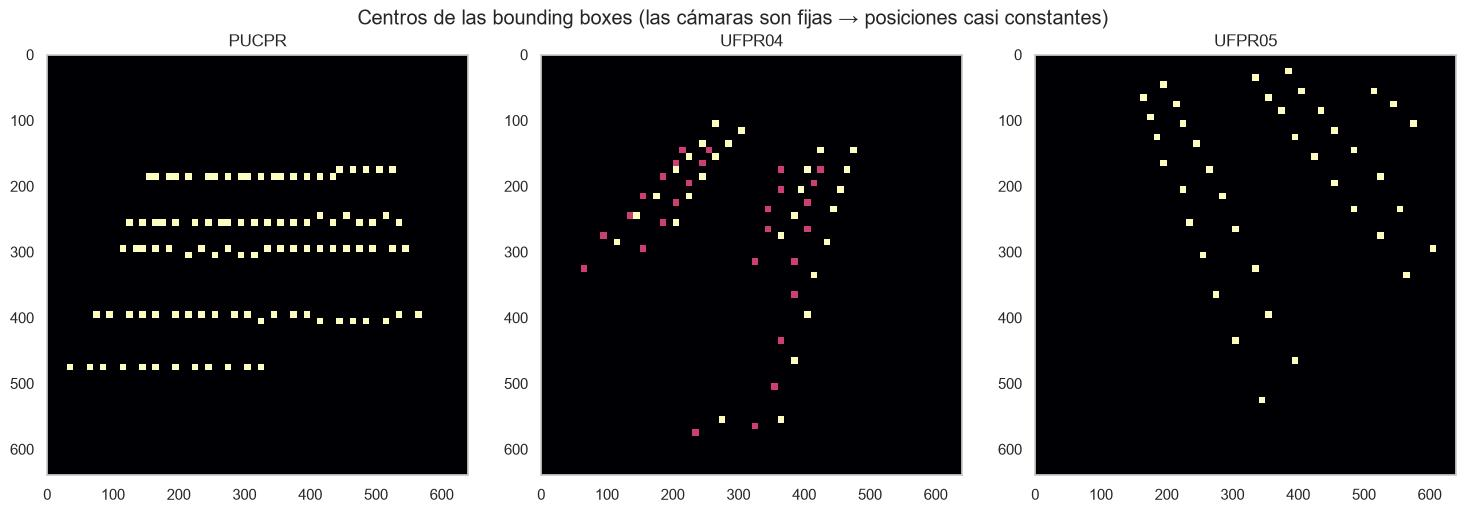

In [12]:
# ¿Dónde caen las cajas? Heatmap de centros por cámara
annots["cx"] = annots["x"] + annots["w"] / 2
annots["cy"] = annots["y"] + annots["h"] / 2

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, cam in zip(ax, cams):
    d = annots[annots["camera"] == cam]
    a.hist2d(d["cx"], d["cy"], bins=64, range=[[0, 640], [0, 640]], cmap="magma")
    a.invert_yaxis(); a.set_aspect("equal"); a.set_title(cam)
plt.suptitle("Centros de las bounding boxes (las cámaras son fijas → posiciones casi constantes)")
plt.tight_layout()

### Solapamiento entre cajas vecinas

Al convertir rectángulos rotados a cajas alineadas a los ejes, las cajas de plazas contiguas pueden
superponerse. Esto importa para el **NMS** del detector: si el umbral de IoU del NMS es muy bajo,
el modelo podría suprimir plazas verdaderas que están pegadas.

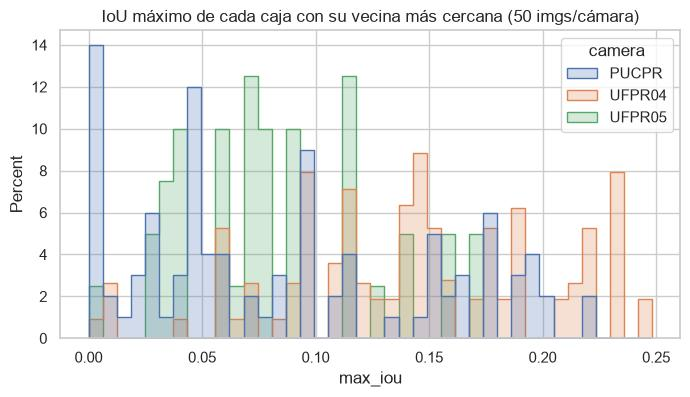

,count,mean,std,min,50%,90%,99%,max
camera,,,,,,,,
PUCPR,5000.0,0.086,0.067,0.0,0.065,0.191,0.223,0.223
UFPR04,1400.0,0.143,0.058,0.0,0.143,0.219,0.248,0.248
UFPR05,2000.0,0.082,0.042,0.0,0.074,0.144,0.168,0.168


In [13]:
def max_iou_per_box(boxes: np.ndarray) -> np.ndarray:
    # boxes: (N, 4) en formato xywh. Devuelve el IoU máximo de cada caja contra las demás.
    x1, y1 = boxes[:, 0], boxes[:, 1]
    x2, y2 = x1 + boxes[:, 2], y1 + boxes[:, 3]
    iw = np.clip(np.minimum(x2[:, None], x2) - np.maximum(x1[:, None], x1), 0, None)
    ih = np.clip(np.minimum(y2[:, None], y2) - np.maximum(y1[:, None], y1), 0, None)
    inter = iw * ih
    area = boxes[:, 2] * boxes[:, 3]
    iou = inter / (area[:, None] + area - inter)
    np.fill_diagonal(iou, 0)
    return iou.max(axis=1)


rows = []
for cam in cams:
    ids = images[(images["camera"] == cam) & (images["split"] == "train")].sample(50, random_state=0)["image_id"]
    for iid in ids:
        b = annots.loc[(annots["split"] == "train") & (annots["image_id"] == iid), ["x", "y", "w", "h"]].to_numpy(float)
        rows += [{"camera": cam, "max_iou": v} for v in max_iou_per_box(b)]
iou_df = pd.DataFrame(rows)

plt.figure(figsize=(8, 4))
sns.histplot(data=iou_df, x="max_iou", hue="camera", bins=40, element="step", stat="percent", common_norm=False)
plt.title("IoU máximo de cada caja con su vecina más cercana (50 imgs/cámara)")
plt.show()
iou_df.groupby("camera")["max_iou"].describe(percentiles=[0.5, 0.9, 0.99]).round(3)

## 7. Visualización de ejemplos

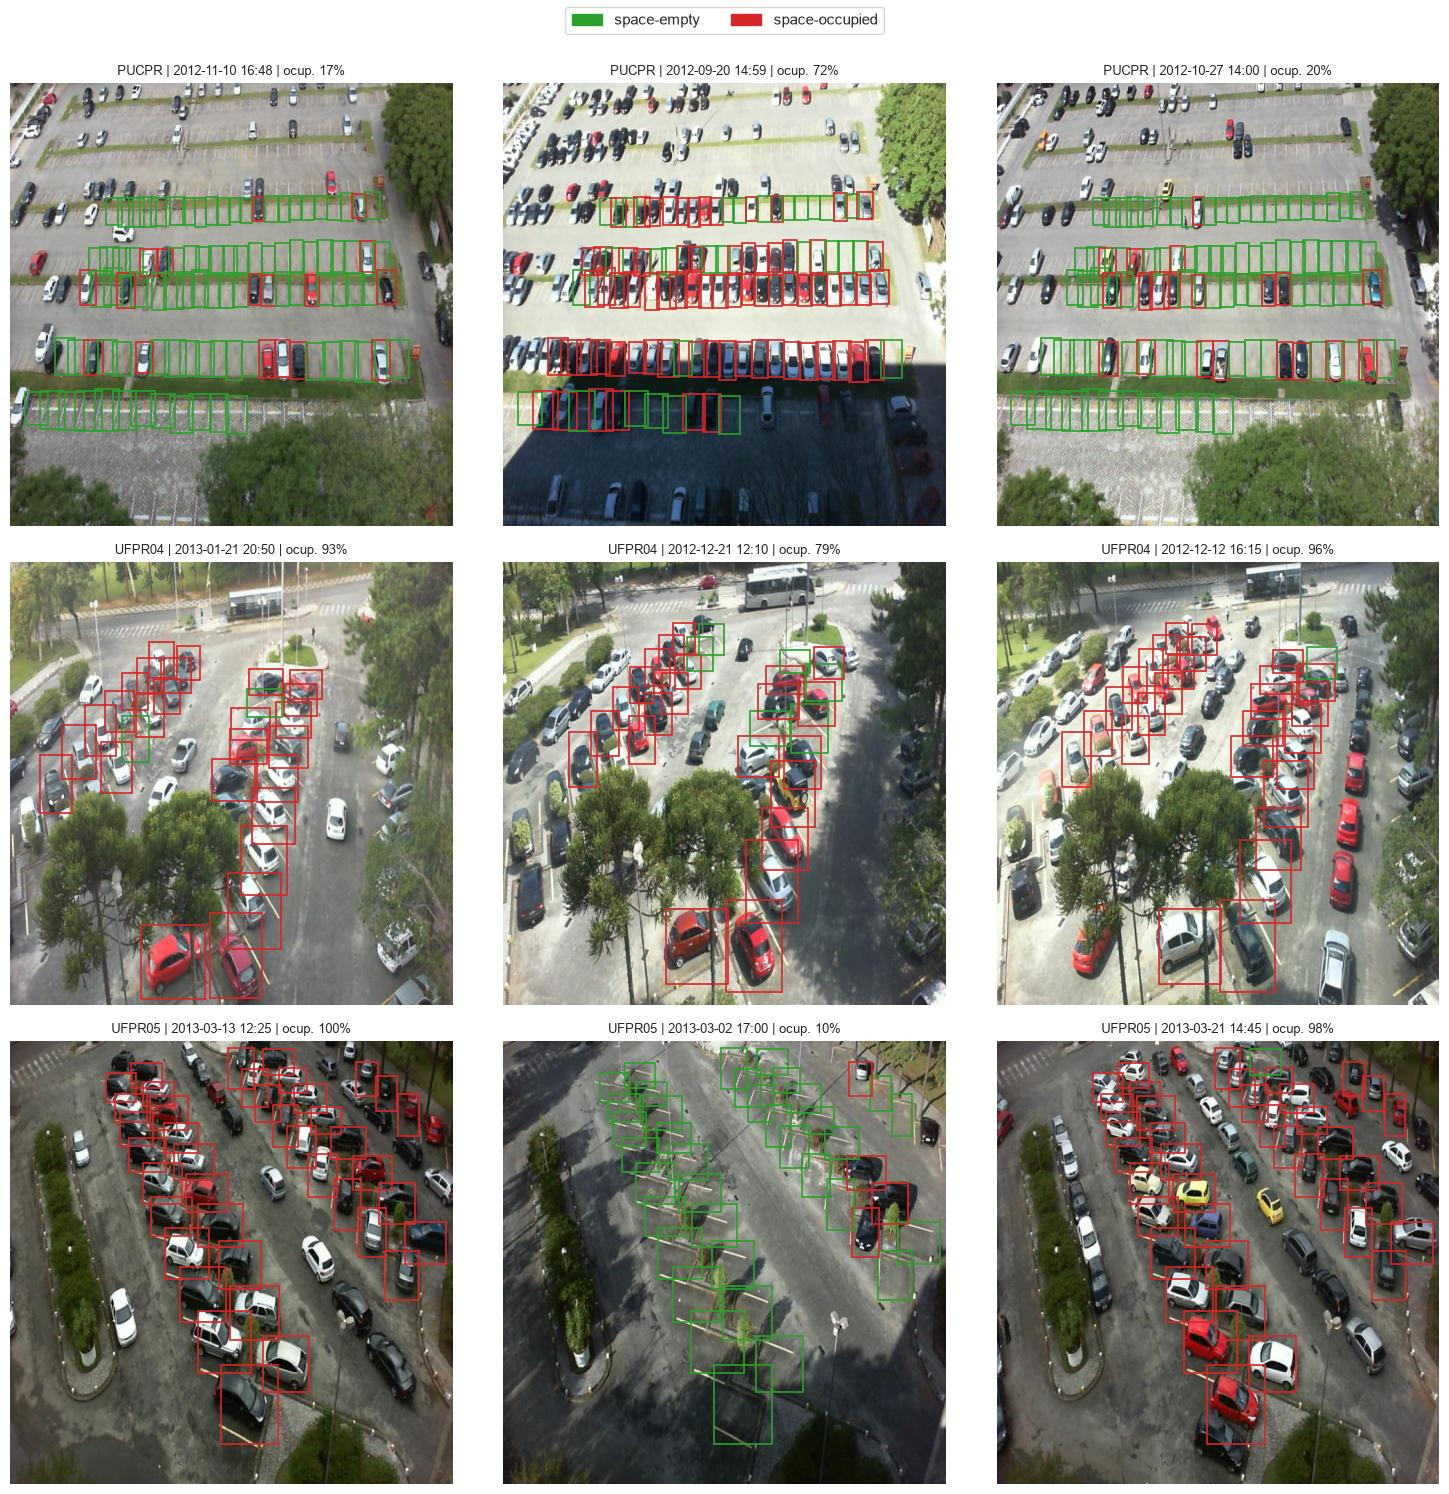

In [14]:
def show_image(split: str, image_id: int, ax=None, title: str | None = None):
    row = images[(images["split"] == split) & (images["image_id"] == image_id)].iloc[0]
    img = Image.open(DATA_DIR / split / row["file_name"])
    ax = ax or plt.gca()
    ax.imshow(img)
    for _, a in annots[(annots["split"] == split) & (annots["image_id"] == image_id)].iterrows():
        ax.add_patch(mpatches.Rectangle((a["x"], a["y"]), a["w"], a["h"], fill=False,
                                        lw=1.2, ec=PALETTE.get(a["category"], "yellow")))
    occ_txt = "" if pd.isna(row["occupancy"]) else f" | ocup. {row['occupancy']:.0%}"
    ax.set_title(title or f"{row['camera']} | {row['datetime']:%Y-%m-%d %H:%M}{occ_txt}", fontsize=9)
    ax.axis("off")


fig, axes = plt.subplots(3, 3, figsize=(15, 15))
for r, cam in enumerate(cams):
    sel = images[(images["camera"] == cam) & (images["split"] == "train")].sample(3, random_state=1)
    for c, (_, row) in enumerate(sel.iterrows()):
        show_image("train", row["image_id"], axes[r, c])
fig.legend(handles=[mpatches.Patch(color=v, label=k) for k, v in PALETTE.items()], loc="upper center", ncol=2)
plt.tight_layout(rect=(0, 0, 1, 0.97))

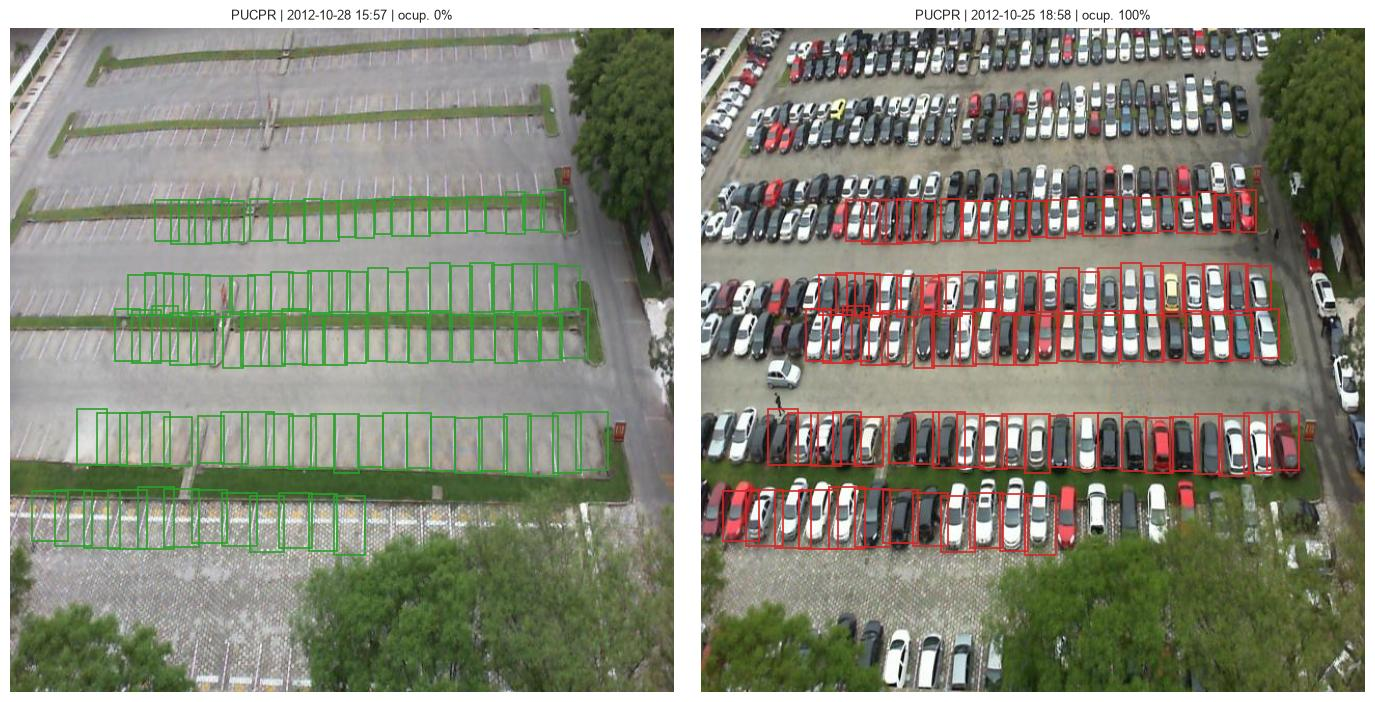

In [15]:
# Misma cámara, ocupación baja vs alta
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
d = images[(images["camera"] == "PUCPR") & (images["split"] == "train")].sort_values("occupancy")
show_image("train", d.iloc[0]["image_id"], axes[0])
show_image("train", d.iloc[-1]["image_id"], axes[1])
plt.tight_layout()

### Imágenes sin anotaciones

Hay 274 imágenes (2,2%) sin ninguna caja. Si se usaran como *background*, el modelo aprendería que
ahí no hay plazas.

{'train': 189, 'valid': 59, 'test': 26}


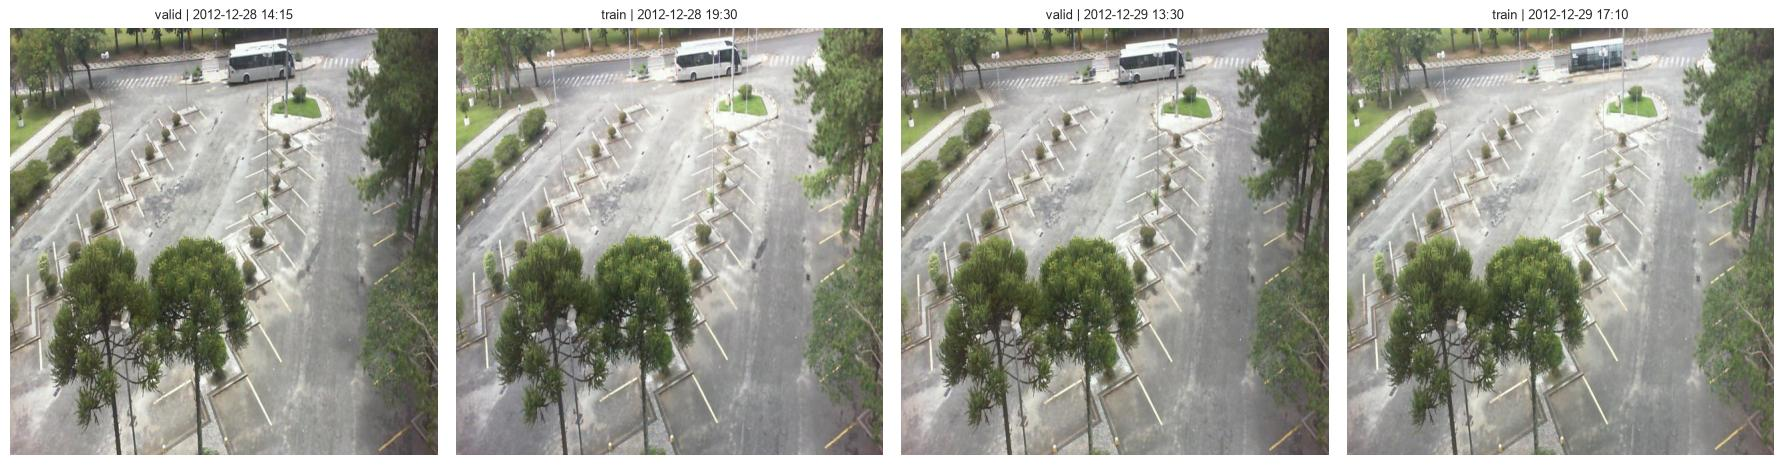

In [16]:
empty_imgs = images[images["n_annots"] == 0]
print(empty_imgs["split"].value_counts().to_dict())
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for a, (_, row) in zip(axes, empty_imgs.sample(4, random_state=3).iterrows()):
    show_image(row["split"], row["image_id"], a, title=f"{row['split']} | {row['datetime']:%Y-%m-%d %H:%M}")
plt.tight_layout()

**Observación:** las imágenes sin anotar son de **UFPR04 con el estacionamiento vacío**: las plazas existen pero
no fueron etiquetadas. Son **errores de anotación** → hay que **descartarlas** del entrenamiento y la evaluación
(si quedan en test, cada plaza libre detectada contaría como falso positivo).

**Observación 2:** en los ejemplos de arriba se ve que **sólo un subconjunto de las plazas visibles está anotado**
(p. ej. en PUCPR las filas superiores y la inferior no tienen cajas, y en UFPR04/05 hay autos estacionados sin caja).
El detector va a aprender "plazas de esta zona" y no "cualquier plaza". Consecuencias:

- Detecciones en zonas no anotadas cuentan como falsos positivos → la *precision* sobre este dataset subestima al modelo.
- Para la demo en video habrá que **definir una ROI** (o filtrar por las plazas de interés) en el estacionamiento nuevo.

## 8. Iluminación

Sin la etiqueta de clima, usamos el **brillo medio** de la imagen como proxy de las condiciones
(sol / nublado / lluvia / atardecer). Calculado sobre una muestra para no leer las 12k imágenes.

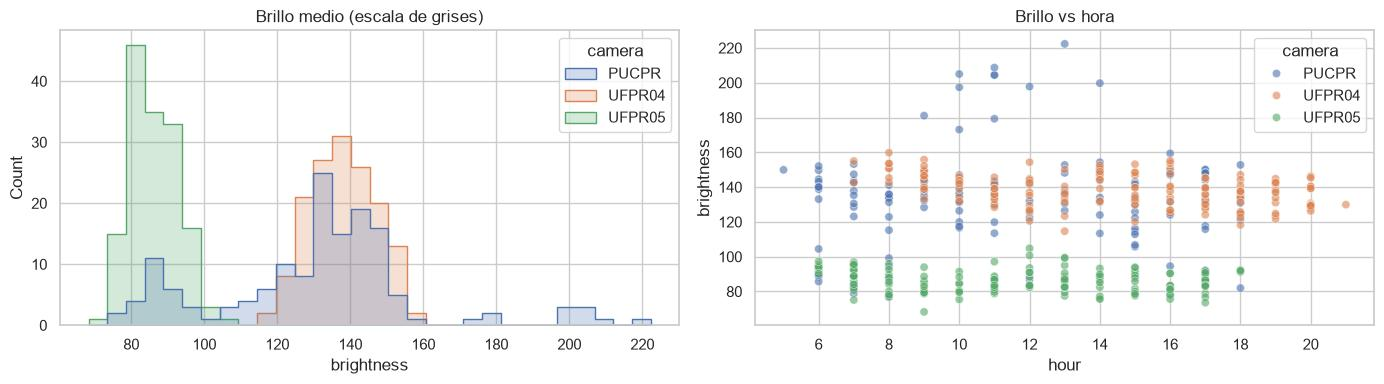

In [17]:
def mean_brightness(split, fname):
    return np.asarray(Image.open(DATA_DIR / split / fname).convert("L"), dtype=np.float32).mean()


bright = images[images["camera"].isin(cams)].groupby("camera", group_keys=False).sample(150, random_state=0).copy()
bright["brightness"] = [mean_brightness(s, f) for s, f in zip(bright["split"], bright["file_name"])]

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(data=bright, x="brightness", hue="camera", bins=30, element="step", ax=ax[0])
ax[0].set_title("Brillo medio (escala de grises)")
sns.scatterplot(data=bright, x="hour", y="brightness", hue="camera", alpha=0.6, ax=ax[1])
ax[1].set_title("Brillo vs hora")
plt.tight_layout()

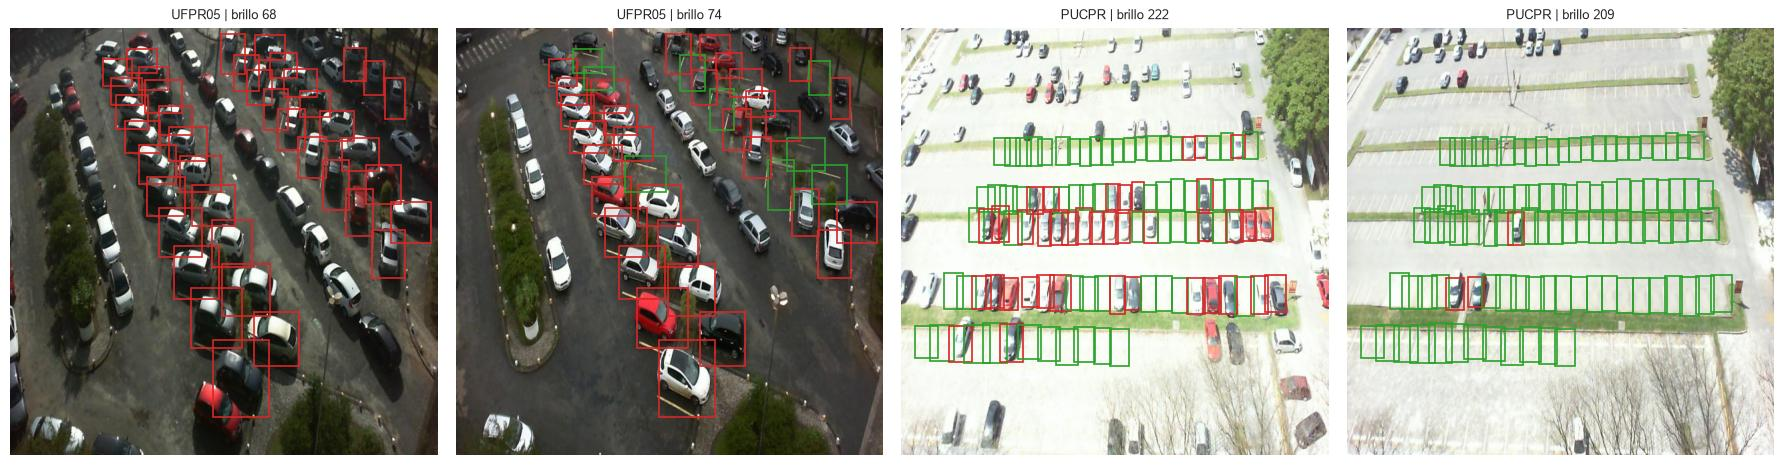

In [18]:
# Extremos de iluminación
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
ext = pd.concat([bright.nsmallest(2, "brightness"), bright.nlargest(2, "brightness")])
for a, (_, row) in zip(axes, ext.iterrows()):
    show_image(row["split"], row["image_id"], a, title=f"{row['camera']} | brillo {row['brightness']:.0f}")
plt.tight_layout()

## 9. Riesgo de *data leakage*

El split de Roboflow es **aleatorio por imagen**. Como las cámaras son fijas y los frames se toman cada pocos
minutos, frames casi idénticos (mismo día, minutos de diferencia, mismos autos estacionados) quedan
repartidos entre train, valid y test. Eso **infla las métricas** de test.

In [19]:
days = {s: set(images.loc[images["split"] == s, "date"]) for s in SPLITS}
for s in ["valid", "test"]:
    shared = days[s] & days["train"]
    print(f"Días de {s} que también aparecen en train: {len(shared)}/{len(days[s])}")

# Distancia temporal de cada imagen de test a la imagen de train más cercana (misma cámara)
tr = images[images["split"] == "train"].sort_values("datetime")
te = images[images["split"] == "test"].sort_values("datetime")
near = pd.merge_asof(te, tr[["datetime", "camera"]].rename(columns={"datetime": "dt_train"}),
                     left_on="datetime", right_on="dt_train", by="camera", direction="nearest")
near["gap_min"] = (near["datetime"] - near["dt_train"]).abs().dt.total_seconds() / 60
print("\nMinutos hasta el frame de train más cercano (misma cámara):")
print(near["gap_min"].describe(percentiles=[0.5, 0.9]).round(1))

Días de valid que también aparecen en train: 99/99
Días de test que también aparecen en train: 96/96

Minutos hasta el frame de train más cercano (misma cámara):
count    1242.0
mean        5.6
std         1.9
min         0.1
50%         5.0
90%        10.0
max        20.0
Name: gap_min, dtype: float64


**Propuesta:** además de reportar métricas sobre el split oficial (para comparar con otros trabajos),
armar un **split por día** (todos los frames de un día en un solo split) y/o un **split por cámara**
(entrenar en dos cámaras y evaluar en la tercera) para medir generalización real. Esto es especialmente
relevante para la demo en video, que será sobre un estacionamiento que el modelo nunca vio.

## 10. Conclusiones y próximos pasos

**Sobre el dataset**

- 12.416 imágenes 640×640 (train 8.691 / valid 2.483 / test 1.242), ~712k cajas, 2 clases útiles:
  `space-empty` y `space-occupied`, **razonablemente balanceadas** (~53% / 47%). `spaces` (id 0) no se usa.
- 3 cámaras fijas recuperables por cantidad de plazas: PUCPR (100), UFPR05 (40), UFPR04 (28). Se perdieron
  la cámara y el clima en el export de Roboflow.
- 274 imágenes (2,2%, todas UFPR04 vacío) **sin anotaciones** por error de etiquetado → **descartarlas**.
- **Anotación parcial**: sólo un subconjunto de las plazas visibles tiene caja → afecta la precision medida y
  obliga a definir una ROI en la demo.
- Objetos **chicos/medianos** (sqrt(área) entre ~23 y ~103 px a 640; en PUCPR el 51% son *small* según COCO)
  y hasta 100 cajas por imagen → cuidar `imgsz` (probar >640 no aporta, la fuente ya es 640) y `max_det`.
- El solapamiento entre cajas vecinas es bajo (IoU máx. ≈ 0,25) → el NMS por defecto (IoU 0,45–0,7) no
  debería suprimir plazas contiguas.
- Imágenes estiradas (1280×720 → 640×640): en inferencia sobre video hay que aplicar el mismo preprocesamiento
  o reentrenar con *letterbox*.
- **Leakage** temporal fuerte: todos los días de valid/test están en train y la mediana de distancia de un frame
  de test al frame de train más cercano (misma cámara) es **5 minutos** → evaluar también con split por día / por cámara.

**Posibles próximos pasos**

1. Convertir anotaciones COCO → formato YOLO (Ultralytics) y dejar el COCO para torchvision/Detectron.
2. Entrenar y comparar al menos dos arquitecturas, p. ej.:
   - **One-stage:** YOLOv8/YOLO11 (Ultralytics).
   - **Two-stage o transformer:** Faster R-CNN (torchvision) o RT-DETR.
3. Métricas: precision, recall, F1, mAP@0.5 y mAP@0.5:0.95 (global, por clase y por cámara), y tiempo de
   inferencia (ms/imagen, FPS) en el mismo hardware.
4. Post-proceso: % de ocupación por frame (ocupados / total detectado) y comparación con el ground truth.
5. Demo: conseguir un video corto de un estacionamiento (vista elevada fija), inferir frame a frame y
   superponer conteo de libres/ocupados. Evaluar suavizado temporal para estabilizar el conteo.